# 2D Robot Path Planning — A* vs RRT


## 0. Thiết lập môi trường

In [13]:
from pathlib import Path
import sys
import math
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt

# Tìm project root dù kernel khởi chạy ở root hoặc notebooks/.
workdir = Path.cwd().resolve()
root = next((p for p in (workdir, *workdir.parents) if (p / "src" / "path_planning").is_dir()), None)
if root is None:
    raise FileNotFoundError("Không tìm thấy src/path_planning. Hãy mở notebook trong repository.")
sys.path.insert(0, str(root / "src"))

from path_planning.maps import example_map, create_grid_map
from path_planning.astar import astar
from path_planning.rrt import rrt
from path_planning.collision import point_free, segment_free
from path_planning.metrics import path_length, summarize
from path_planning.benchmark import benchmark, save_csv

print("Project root:", root)
print("Python:", sys.version.split()[0])

Project root: D:\local-repo\2d-robot-path-planning\2D-Robot-Path-Planning
Python: 3.12.10


## 1. Occupancy Grid Map

Bản đồ là ma trận `grid[x, y]`: **0 = ô trống**, **1 = ô bị chiếm**. Mỗi ô là hình vuông đơn vị. Trục hiển thị được chuyển vị `grid.T` để `x` nằm ngang và `y` nằm dọc. Start/Goal được đặt tại tâm ô (`+0.5`).

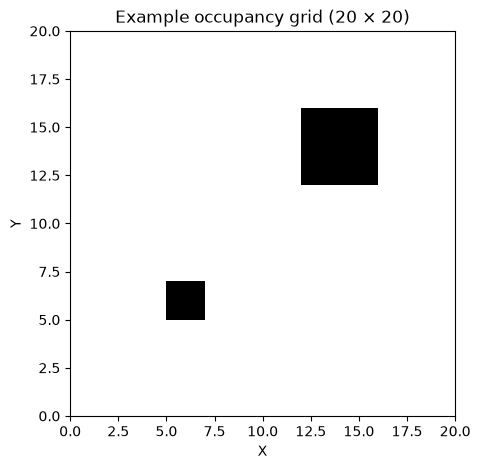

In [14]:
small = example_map()
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(small.T, origin="lower", cmap="gray_r", interpolation="nearest", extent=(0, 20, 0, 20))
ax.set(title="Example occupancy grid (20 × 20)", xlabel="X", ylabel="Y")
plt.show()

Grid shape: (100, 100)
Occupied cells: 491


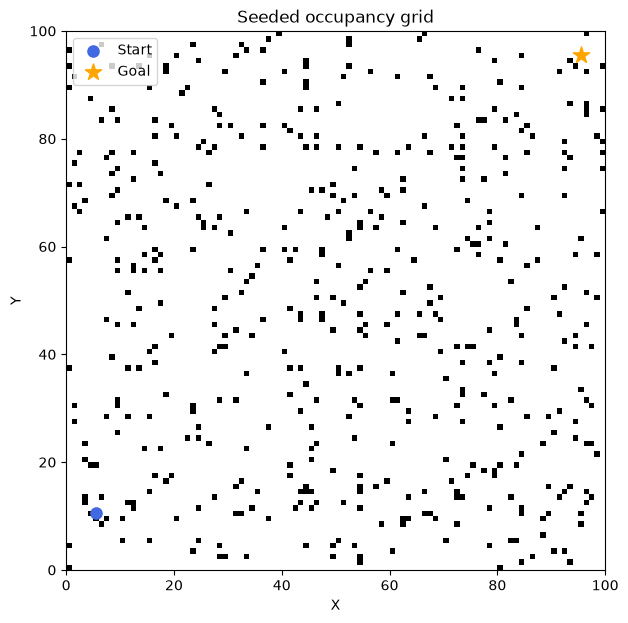

In [15]:
SIZE = (100, 100)
START = (5, 10)
GOAL = (95, 95)
SEED = 42
OBSTACLES = 500  # số lần đặt vật cản, không phải số ô bị chiếm duy nhất

grid = create_grid_map(size=SIZE, obstacle_count=OBSTACLES, start=START, goal=GOAL, seed=SEED)
print("Grid shape:", grid.shape)
print("Occupied cells:", int(grid.sum()))
assert grid[START] == 0 and grid[GOAL] == 0

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(grid.T, origin="lower", cmap="gray_r", interpolation="nearest", extent=(0, SIZE[0], 0, SIZE[1]))
ax.scatter(START[0]+.5, START[1]+.5, c="royalblue", s=65, label="Start", zorder=5)
ax.scatter(GOAL[0]+.5, GOAL[1]+.5, c="orange", marker="*", s=150, label="Goal", zorder=5)
ax.set(title="Seeded occupancy grid", xlabel="X", ylabel="Y")
ax.legend(); plt.show()


## 2. Thuật toán A* Search

A* ưu tiên mở rộng node có giá trị hàm đánh giá nhỏ nhất:

$$
f(n) = g(n) + h(n)
$$

Trong đó:

- $g(n)$: Tổng chi phí các bước đã đi từ Start đến node $n$.
- $h(n)$: Ước lượng khoảng cách Euclid từ node $n$ đến Goal.
- $f(n)$: Tổng chi phí thực tế và chi phí ước lượng.

**Heuristic Euclidean Distance:**

$$
h(n) = \sqrt{(x_n-x_g)^2 + (y_n-y_g)^2}
$$

**Chi phí di chuyển:**

- Di chuyển ngang hoặc dọc: $1$.
- Di chuyển chéo: $\sqrt{2}$.
- Không cho phép đi chéo cắt góc qua vật cản.

Với heuristic nhất quán này, A* tìm được đường đi tối ưu trên đồ thị lưới 8 hướng đã định nghĩa.


In [16]:
t0 = perf_counter()
astar_path, expanded = astar(grid, START, GOAL)
astar_ms = (perf_counter()-t0)*1000
print(f"A*: success={astar_path is not None}, expanded={len(expanded)}, "
      f"path length={path_length(astar_path)}, time={astar_ms:.2f} ms")

A*: success=True, expanded=1945, path length=128.72287142747453, time=95.98 ms


### Trực quan hóa A*: vùng đã mở rộng và đường đi

Các điểm xanh nhạt là **node đã mở rộng**, không đồng nghĩa với đường đi tối ưu. Đường đỏ là đường đi trả về.

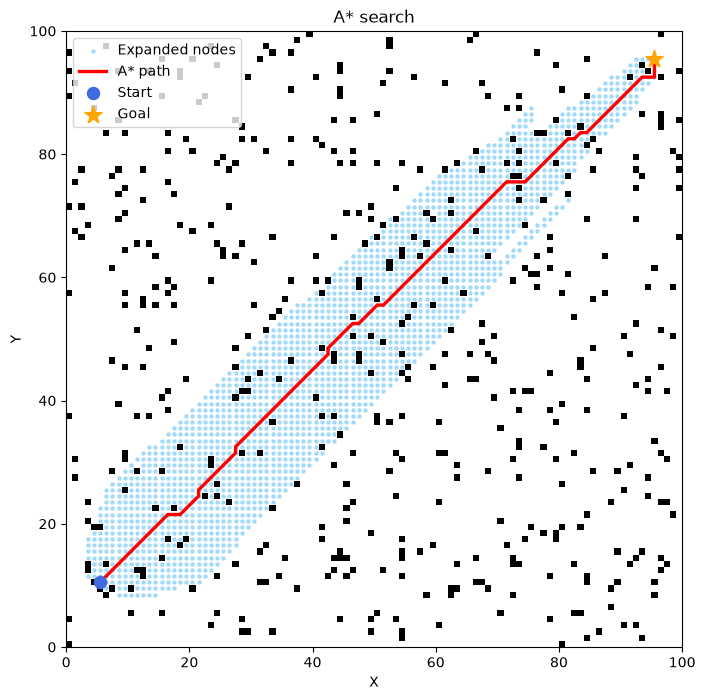

In [17]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(grid.T, origin="lower", cmap="gray_r", interpolation="nearest", extent=(0, SIZE[0], 0, SIZE[1]))
if expanded:
    xy = np.asarray(expanded, dtype=float)+.5
    ax.scatter(xy[:,0], xy[:,1], s=5, c="lightskyblue", alpha=.65, label="Expanded nodes")
if astar_path:
    xy = np.asarray(astar_path, dtype=float)+.5
    ax.plot(xy[:,0], xy[:,1], "r-", lw=2.4, label="A* path")
ax.scatter(START[0]+.5, START[1]+.5, c="royalblue", s=75, label="Start", zorder=6)
ax.scatter(GOAL[0]+.5, GOAL[1]+.5, c="orange", marker="*", s=170, label="Goal", zorder=6)
ax.set(title="A* search", xlabel="X", ylabel="Y"); ax.legend(); plt.show()

## 3. Thuật toán RRT (Rapidly-exploring Random Tree)

RRT phát triển cây bằng cách: lấy mẫu ngẫu nhiên → tìm node gần nhất theo **khoảng cách Euclid bình phương** → tiến một bước giới hạn (`step_size`) → kiểm tra va chạm trên toàn đoạn → thêm node vào cây.

- `goal_sample_rate=0.10`: 10% lấy mẫu trực tiếp tại Goal.
- `step_size=3.0`: giới hạn bước tiến.
- `max_iter=5000`: giới hạn lần lấy mẫu.
- RRT hoạt động trong **tọa độ liên tục**, khác với đồ thị 8 hướng của A*.
- RRT **không bảo đảm đường đi ngắn nhất**.

In [18]:
t0 = perf_counter()
rrt_path, tree = rrt(grid, START, GOAL, step_size=3.0, max_iter=5000,
                     goal_threshold=3.0, goal_sample_rate=0.10, seed=42)
rrt_ms = (perf_counter()-t0)*1000
print(f"RRT: success={rrt_path is not None}, tree nodes={len(tree)}, "
      f"path length={path_length(rrt_path)}, time={rrt_ms:.2f} ms")

RRT: success=True, tree nodes=432, path length=145.12090415100496, time=61.92 ms


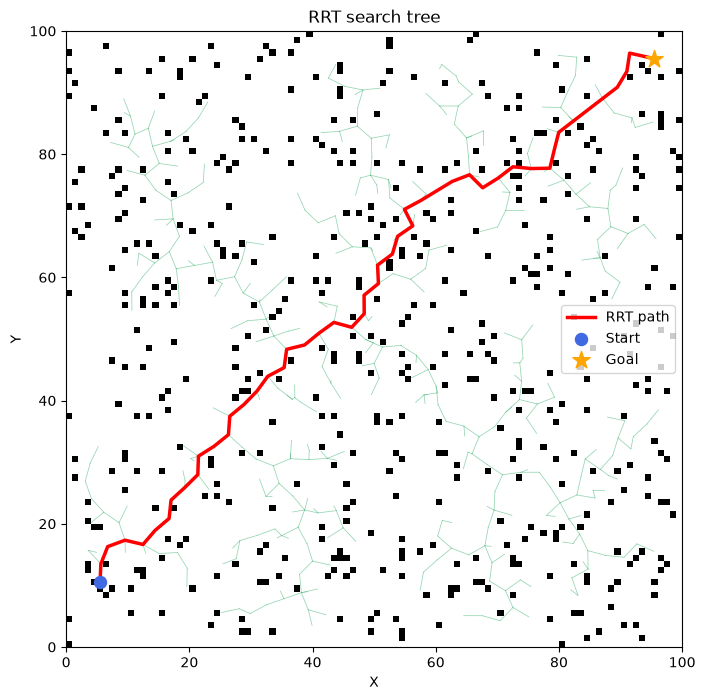

In [19]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(grid.T, origin="lower", cmap="gray_r", interpolation="nearest", extent=(0, SIZE[0], 0, SIZE[1]))
for node in tree:
    if node.parent is not None:
        p = tree[node.parent]
        ax.plot([p.x, node.x], [p.y, node.y], c="mediumseagreen", lw=.55, alpha=.55)
if rrt_path:
    xy = np.asarray(rrt_path)
    ax.plot(xy[:,0], xy[:,1], "r-", lw=2.5, label="RRT path")
ax.scatter(START[0]+.5, START[1]+.5, c="royalblue", s=75, label="Start", zorder=6)
ax.scatter(GOAL[0]+.5, GOAL[1]+.5, c="orange", marker="*", s=170, label="Goal", zorder=6)
ax.set(title="RRT search tree", xlabel="X", ylabel="Y"); ax.legend(); plt.show()

## 4. Kiểm tra tính hợp lệ đường đi

Mỗi cạnh phải nằm trong bản đồ và không giao với ô vật cản. Bộ kiểm tra va chạm xem **chạm biên ô bị chiếm cũng là va chạm**. Kiểm tra cả hai thuật toán với tọa độ tâm ô cho A*.

In [20]:
def valid_path(grid_map, path, expected_start, expected_goal, grid_indices=False):
    if path is None:
        return False
    pts = [(x+.5, y+.5) for x,y in path] if grid_indices else list(path)
    if not pts:
        return False
    s = (expected_start[0]+.5, expected_start[1]+.5)
    g = (expected_goal[0]+.5, expected_goal[1]+.5)
    return (math.dist(pts[0], s)<1e-8 and math.dist(pts[-1],g)<1e-8
            and all(point_free(grid_map, p) for p in pts)
            and all(segment_free(grid_map, a, b) for a,b in zip(pts,pts[1:])))

print("A* path valid:", valid_path(grid, astar_path, START, GOAL, grid_indices=True))
print("RRT path valid:", valid_path(grid, rrt_path, START, GOAL))
assert astar_path is not None and valid_path(grid, astar_path, START, GOAL, grid_indices=True)
assert rrt_path is not None and valid_path(grid, rrt_path, START, GOAL)

A* path valid: True
RRT path valid: True


## 5. So sánh kết quả trên cùng bản đồ

**Chú ý:** thời gian chạy phụ thuộc máy, còn `expanded nodes` (A*) và `tree nodes` (RRT) là hai khái niệm khác nhau. Không dùng một lần chạy để kết luận thuật toán nào luôn tốt hơn.

In [21]:
from IPython.display import display
comparison = [
    {"Algorithm":"A*", "Success":astar_path is not None,
     "Path length":path_length(astar_path), "Time (ms)":round(astar_ms,3), "Search nodes":len(expanded)},
    {"Algorithm":"RRT", "Success":rrt_path is not None,
     "Path length":path_length(rrt_path), "Time (ms)":round(rrt_ms,3), "Search nodes":len(tree)},
]
for record in comparison:
    print(record)

{'Algorithm': 'A*', 'Success': True, 'Path length': 128.72287142747453, 'Time (ms)': 95.979, 'Search nodes': 1945}
{'Algorithm': 'RRT', 'Success': True, 'Path length': 145.12090415100496, 'Time (ms)': 61.92, 'Search nodes': 432}


## 6. Benchmark tái lập trên nhiều bản đồ

Mỗi mức vật cản dùng cùng bộ seed cho A* và RRT. RRT dùng seed riêng để điều khiển lấy mẫu. Số lần đặt vật cản có thể trùng nhau.

Để notebook chạy nhanh trong lúc kiểm tra, mặc định **3 lần chạy × 3 mức vật cản**. Đổi `RUNS = 20` để tái tạo cấu hình benchmark đầy đủ của README. `max_iter=5000` được giữ nguyên.

In [22]:
LEVELS = (100, 500, 1000)
RUNS = 3  # Đổi thành 20 cho báo cáo benchmark đầy đủ
records = benchmark(levels=LEVELS, runs=RUNS, rrt_iterations=5000)
for level in LEVELS:
    print(f"\nObstacle placement attempts: {level}")
    for name in ("A*", "RRT"):
        subset = [r for r in records if r["obstacles"]==level and r["algorithm"]==name]
        stats = summarize(subset)
        print(f"{name:3s}: {stats}")


Obstacle placement attempts: 100
A* : {'runs': 3, 'success_rate': 100.0, 'mean_time_ms': 43.05163333333333, 'mean_path_length': 125.40341494758871, 'mean_nodes': 671.6666666666666}
RRT: {'runs': 3, 'success_rate': 100.0, 'mean_time_ms': 9.967233333333333, 'mean_path_length': 148.42196938345162, 'mean_nodes': 182}

Obstacle placement attempts: 500
A* : {'runs': 3, 'success_rate': 100.0, 'mean_time_ms': 87.43513333333334, 'mean_path_length': 127.94182284397198, 'mean_nodes': 1619}
RRT: {'runs': 3, 'success_rate': 100.0, 'mean_time_ms': 67.84903333333334, 'mean_path_length': 158.20272257211664, 'mean_nodes': 444.6666666666667}

Obstacle placement attempts: 1000
A* : {'runs': 3, 'success_rate': 100.0, 'mean_time_ms': 138.6007666666667, 'mean_path_length': 132.6281143449872, 'mean_nodes': 2725.3333333333335}
RRT: {'runs': 3, 'success_rate': 100.0, 'mean_time_ms': 151.1191, 'mean_path_length': 161.67655143854446, 'mean_nodes': 663.6666666666666}


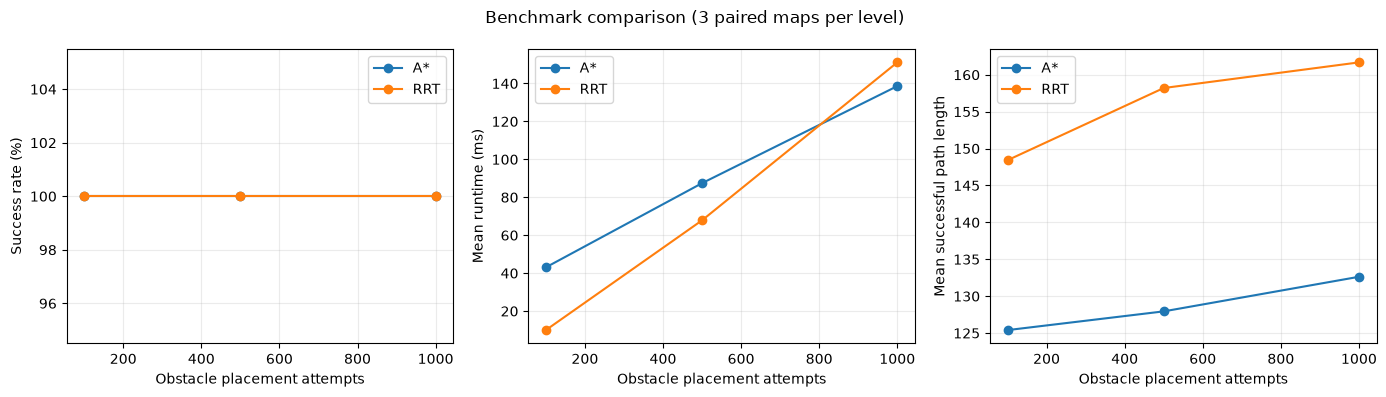

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, ylabel in zip(axes,
    ("success_rate", "mean_time_ms", "mean_path_length"),
    ("Success rate (%)", "Mean runtime (ms)", "Mean successful path length")):
    for name in ("A*", "RRT"):
        values = [summarize([r for r in records if r["obstacles"]==level and r["algorithm"]==name])[metric]
                  for level in LEVELS]
        ax.plot(LEVELS, [np.nan if v is None else v for v in values], marker="o", label=name)
    ax.set(xlabel="Obstacle placement attempts", ylabel=ylabel)
    ax.grid(alpha=.25); ax.legend()
fig.suptitle(f"Benchmark comparison ({RUNS} paired maps per level)")
plt.tight_layout(); plt.show()